In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('../src')

from pathlib import Path
from matplotlib import pyplot as plt
import polars as pl
import numpy as np

data_path = Path('../data')

# Loading data

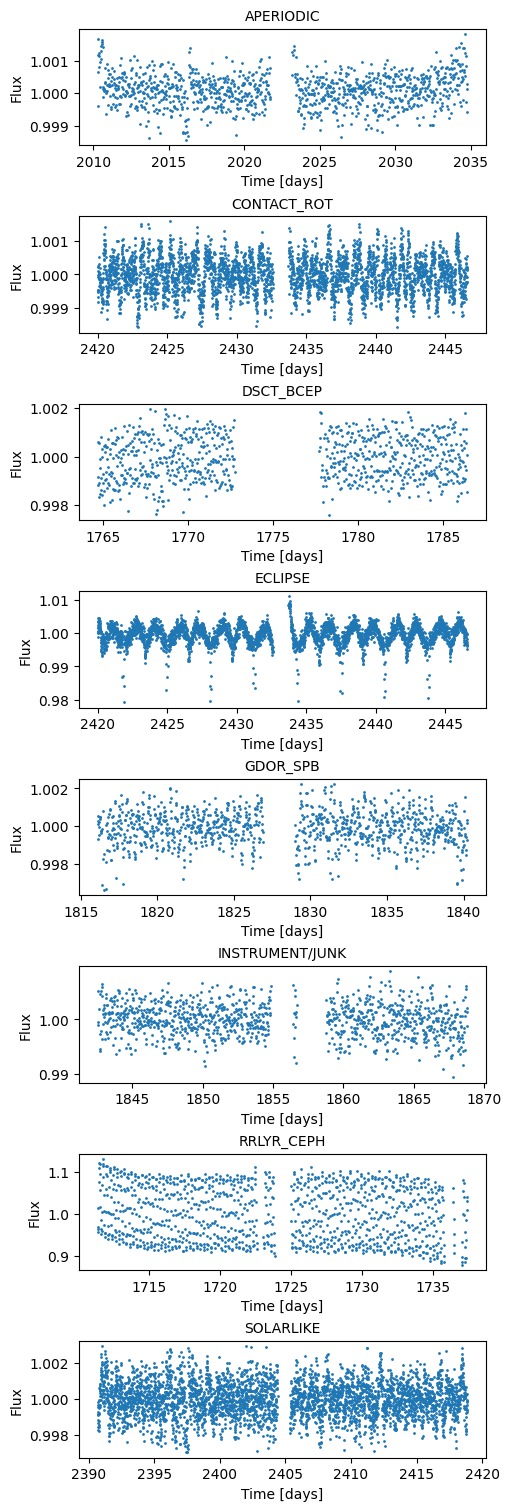

In [2]:
examples = pl.read_csv('../data/random5.csv').with_columns(
    pl.col('time').str.json_decode(pl.List(pl.Float64)),
    pl.col('flux').str.json_decode(pl.List(pl.Float64)),
    pl.col('path').str.split('-').list.get(2).alias('GaiaID').cast(pl.Int64)
).to_dict()
times = [np.array(x) for x in examples['time'].to_list()]
fluxes = [np.array(x) for x in examples['flux'].to_list()]
labels = np.array(examples['label'].to_list())
class_names = np.unique(labels)

fig, axs = plt.subplots(len(class_names), 1, figsize=(5, 15), constrained_layout=True, sharey=False)
for ax, name in zip(axs, class_names):
    idx = np.where(labels == name)[0]
    ax.scatter(times[idx[0]], fluxes[idx[0]], s=1)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('Time [days]')
    ax.set_ylabel('Flux')


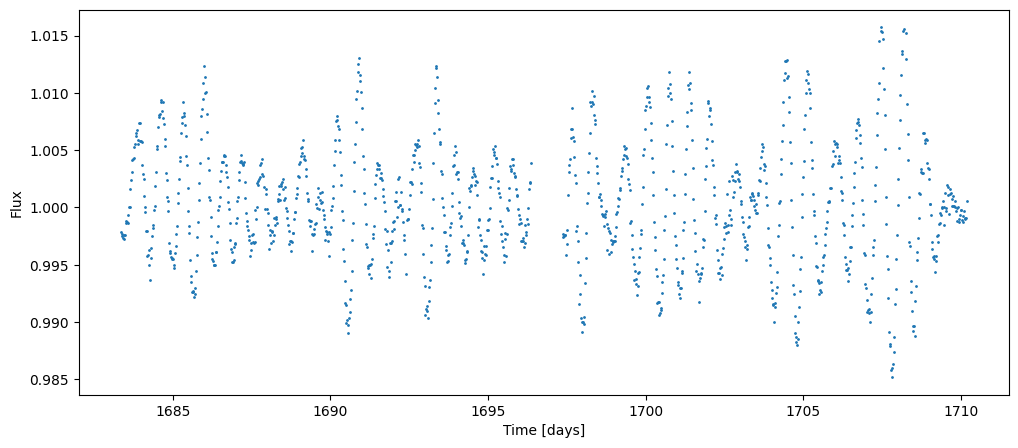

In [3]:
ex_idx = 21
fig, ax = plt.subplots(figsize=(12, 5))
time, flux = times[ex_idx], fluxes[ex_idx]
ax.scatter(time, flux, s=1)
ax.set_xlabel('Time [days]')
ax.set_ylabel('Flux');

# Statistical moments (Time domain)

In [4]:
from time_domain_features import flux_statistics, max_slope

# Classical moments and flux ratios from Richards et al. 2012 and Eyer et al. 2008

display(flux_statistics(flux))
display(max_slope(time, flux))

{'flux_std': 0.005205133702883453,
 'flux_skewness': 0.2144403145232531,
 'flux_kurtosis': 0.017084807858904316,
 'flux_iqr': 0.00680328905582428,
 'flux_amplitude': 0.008864812552928925,
 'flux_mad': 0.0033776462078094482,
 'flux_largest_departure': 0.015772813311673264,
 'flux_percent_difference': 0.017730388653624193,
 'flux_ratio_mid20': 0.14454751368910668,
 'flux_ratio_mid45': 0.266055563259827,
 'flux_ratio_mid50': 0.38372436050982717,
 'flux_ratio_mid65': 0.5316224791248985,
 'flux_ratio_mid80': 0.7541421145304051}

{'max_slope': 0.18826405587851577}

In [5]:
# Computational time for example and for the 40 light curves
%timeit -r10 -n10 flux_statistics(flux)
%timeit -r3 -n3 [flux_statistics(flux) for flux in fluxes]

407 μs ± 14.5 μs per loop (mean ± std. dev. of 10 runs, 10 loops each)
19.9 ms ± 30.5 μs per loop (mean ± std. dev. of 3 runs, 3 loops each)


In [6]:
%timeit -r10 -n10 max_slope(time, flux)
%timeit -r3 -n3 [max_slope(time, flux) for time, flux in zip(times, fluxes)]

23.7 μs ± 5.91 μs per loop (mean ± std. dev. of 10 runs, 10 loops each)
1.18 ms ± 187 μs per loop (mean ± std. dev. of 3 runs, 3 loops each)


# Periodogram features

{'ls_frequency_fundamental': 1.6223963230979364, 'ls_amplitude_fundamental': 0.3205889178727847, 'ls_fap_fundamental': 5.442917042135837e-100, 'ls_entropy': 0.5960879502401466, 'ls_flatness': 0.0341922698356395, 'ls_amplitude_ratio_half_fundamental': 0.02327185159948859, 'ls_frequency_top2': 1.3553536179627357, 'ls_amplitude_ratio_top2_fundamental': 0.5536759238422868, 'ls_distance_to_fundamental_harmonic_top2': 0.5441554564137675, 'ls_closest_harmonic_top2': 0.5, 'ls_frequency_top3': 1.215864830643511, 'ls_amplitude_ratio_top3_fundamental': 0.22380977285336023, 'ls_distance_to_fundamental_harmonic_top3': 0.40466666909454274, 'ls_closest_harmonic_top3': 0.5, 'ls_frequency_top4': 1.4892479352023127, 'ls_amplitude_ratio_top4_fundamental': 0.22201009989149978, 'ls_distance_to_fundamental_harmonic_top4': 0.6780497736533445, 'ls_closest_harmonic_top4': 0.5}


(0.0, 10.0)

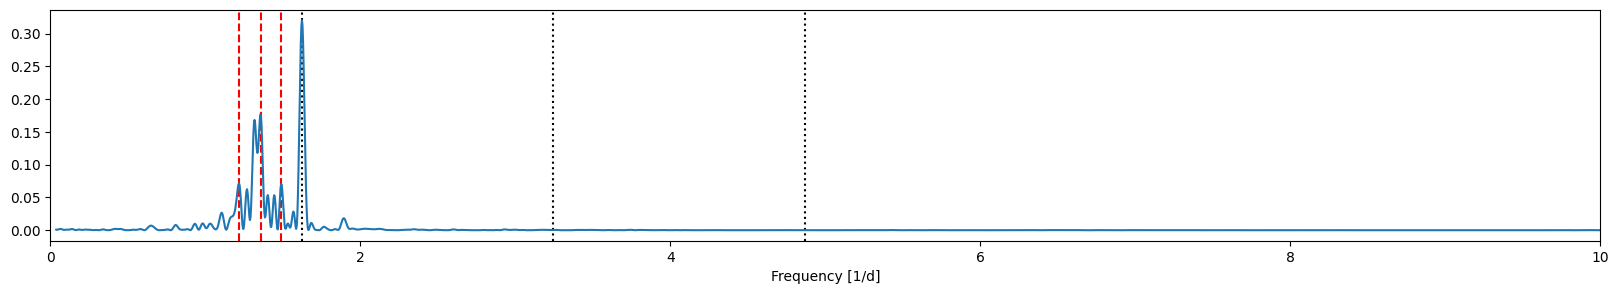

In [7]:
from frequency_domain_features import compute_lombscargle_periodogram, periodogram_features

freqs, ampls, (fmin, fmax, fres) = compute_lombscargle_periodogram(time, flux)
fig, ax = plt.subplots(figsize=(20, 3))
ax.plot(freqs, ampls)
ax.set_xlabel('Frequency [1/d]')

pg = periodogram_features(time, flux)
print(pg)
# ls_frequency_fundamental, ls_amplitude_fundamental, ls_fap_fundamental : The frequency, amplitude and false alarm probability for the peak with maximum power
# ls_entropy/ls_flatness: Attempts to capture the global peak structure (concentrated vs random)
# ls_amplitude_ratio_x_fundamental: The ratio between the power at a given frequency and the dominant/fundamental frequency. Computed for half the fundamental and the top 2/3/4 peaks
# ls_distance_to_fundamental_harmonic_topx: The distance in frequency space between the top 2/3/4 peak frequency and the closest harmonic of the fundamental frequency
# ls_closest_harmonic_topx: The harmonic of the fundamental frequency that is closest in frequency to the top2/3/4 peak

# The top three peaks after the fundamental
ax.axvline(pg['ls_frequency_top2'], ls='--', c='r', zorder=-2)
ax.axvline(pg['ls_frequency_top3'], ls='--', c='r', zorder=-2)
ax.axvline(pg['ls_frequency_top4'], ls='--', c='r', zorder=-2)
for k in range(1, 3+1): # Fundamental frequency and its harmonics
    ax.axvline(pg['ls_frequency_fundamental']*k, ls=':', c='k', zorder=-2)
ax.set_xlim([0, 10])

In [8]:
%timeit -r3 -n3 periodogram_features(time, flux)
%timeit -r3 -n3 [periodogram_features(time, flux) for time, flux in zip(times, fluxes)]

13.8 ms ± 108 μs per loop (mean ± std. dev. of 3 runs, 3 loops each)
697 ms ± 1.11 ms per loop (mean ± std. dev. of 3 runs, 3 loops each)


# Autocorrelation based features

TESS light curves are mostly regularly sampled with the exception of a few big gaps. 

We split the light curve at the gaps the gap regularly sampled sequences, compute the ACF on each segment and then use the average ACF. 

Light curves that end up with no continunous segments longer than four days are discarded

{'acf_lag_first_below_05': 0.12499905962749835,
 'acf_val_lag1': 0.9666716620739578,
 'acf_lag_peak1': 0.6666616513466579,
 'acf_val_peak1': 0.6394451710931376,
 'acf_lag_peak2': 1.3124901260887327,
 'acf_val_peak2': 0.23066275426477317}

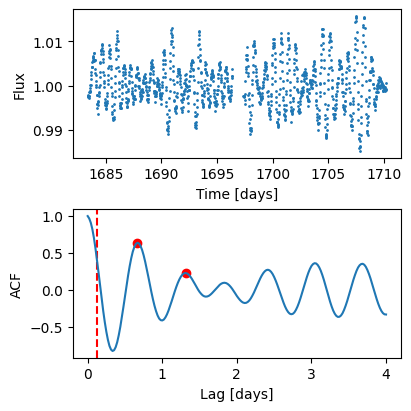

In [9]:
from time_domain_features import autocorrelation_features, acf_fft_from_time_flux

def plot_example_acf(time, flux, axs):
    ax = axs[0]
    ax.scatter(time, flux, s=1)
    ax.set_xlabel('Time [days]')
    ax.set_ylabel('Flux')
    
    lags, rho, dt_nom = acf_fft_from_time_flux(time, flux, 4)
    ax = axs[1]
    ax.plot(lags, rho)
    ax.set_xlabel('Lag [days]')
    ax.set_ylabel('ACF')
    acff = autocorrelation_features(time, flux)
    # acf_lag_first_below_05 : The first time lag where the ACF goes below 0.5
    # acf_val_lag1: The value of the ACF for the first (smallest) lag (equal to the time sampling)
    # acf_val_peakx, acf_lag_peakx: The lag and value of the ACF at the first and second local maxima not taking the zero-lag into account
    ax.scatter([acff['acf_lag_peak1'], acff['acf_lag_peak2']], [acff['acf_val_peak1'], acff['acf_val_peak2']], c='r')
    ax.axvline(acff['acf_lag_first_below_05'], ls='--', c='r', zorder=-1)
    return acff

fig, axs = plt.subplots(2, 1, figsize=(4, 4), constrained_layout=True)
plot_example_acf(time, flux, axs)

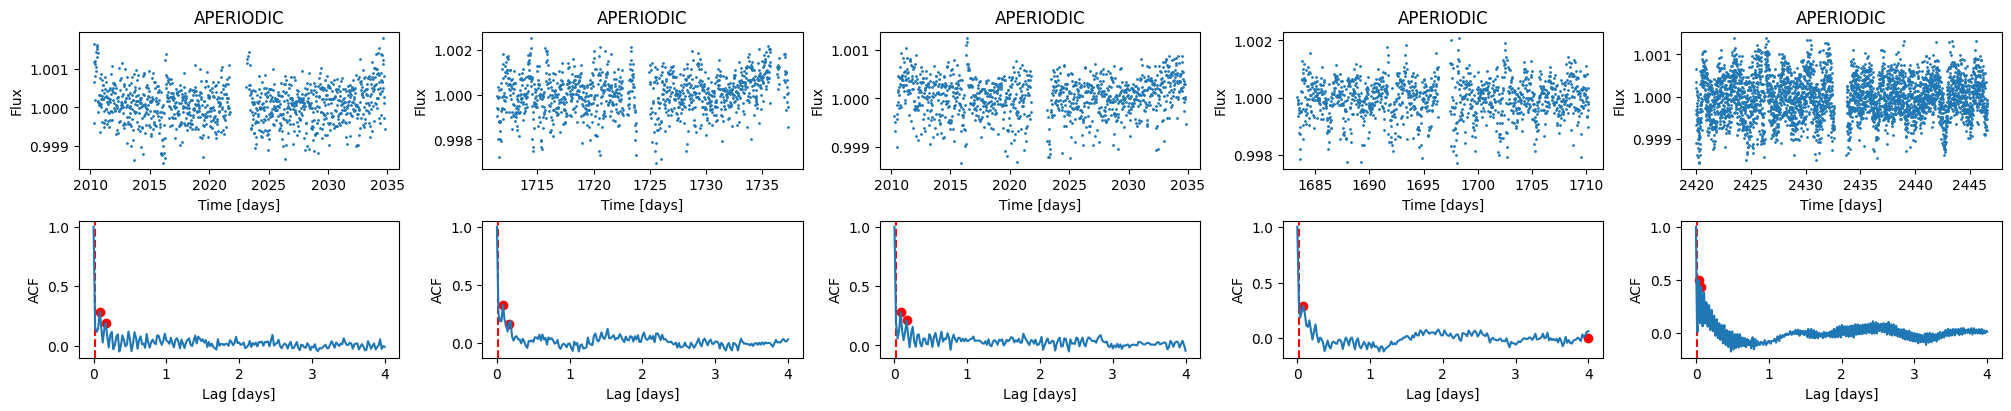

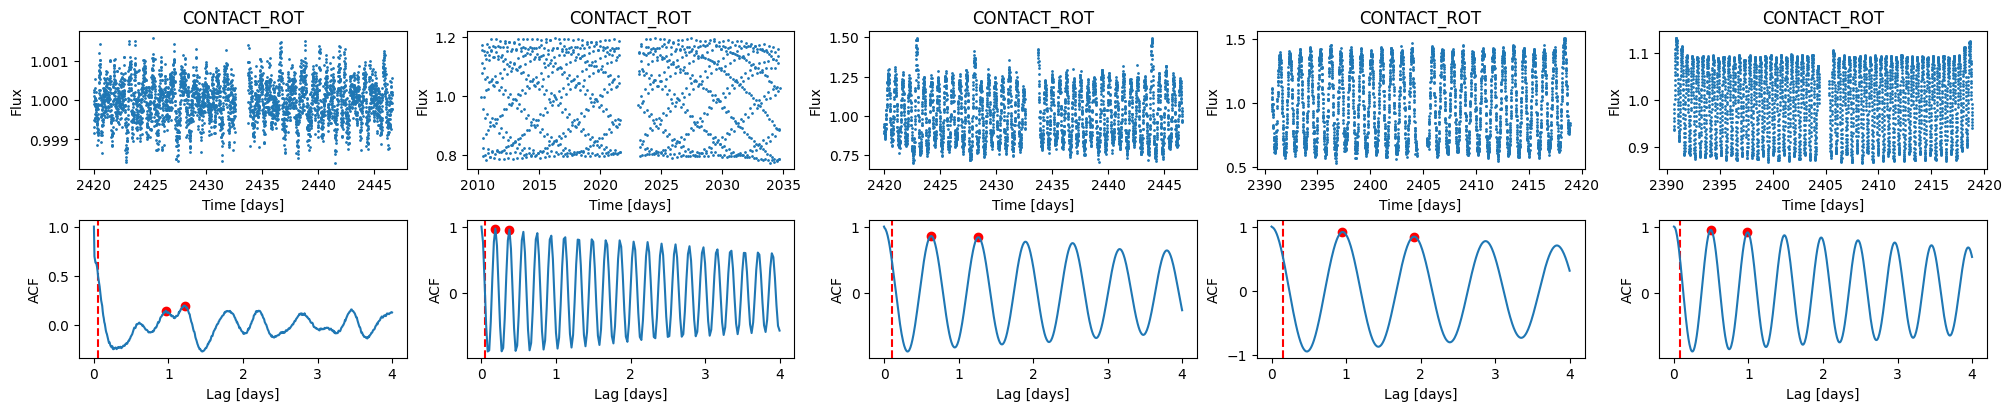

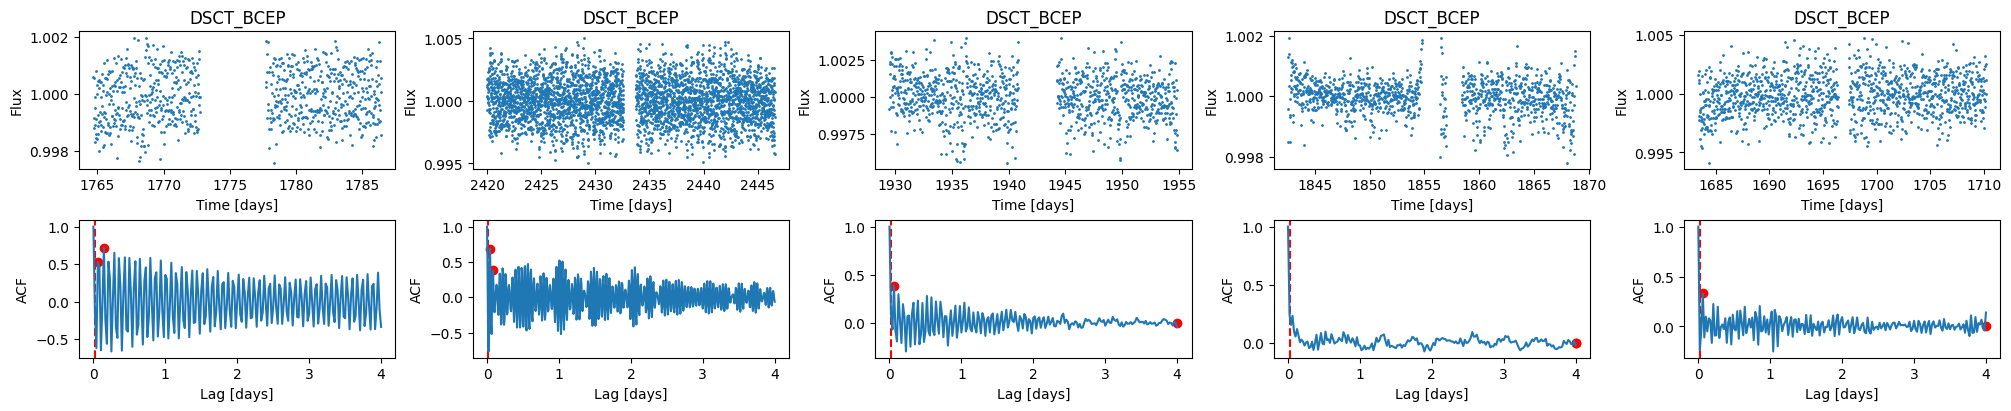

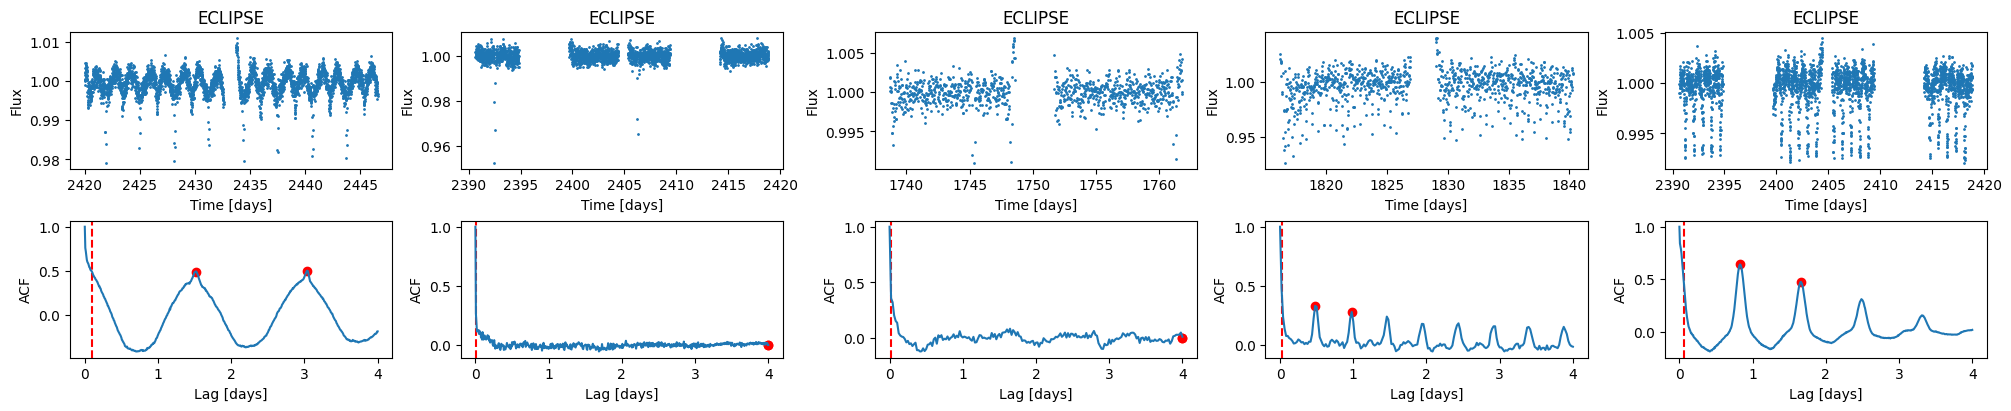

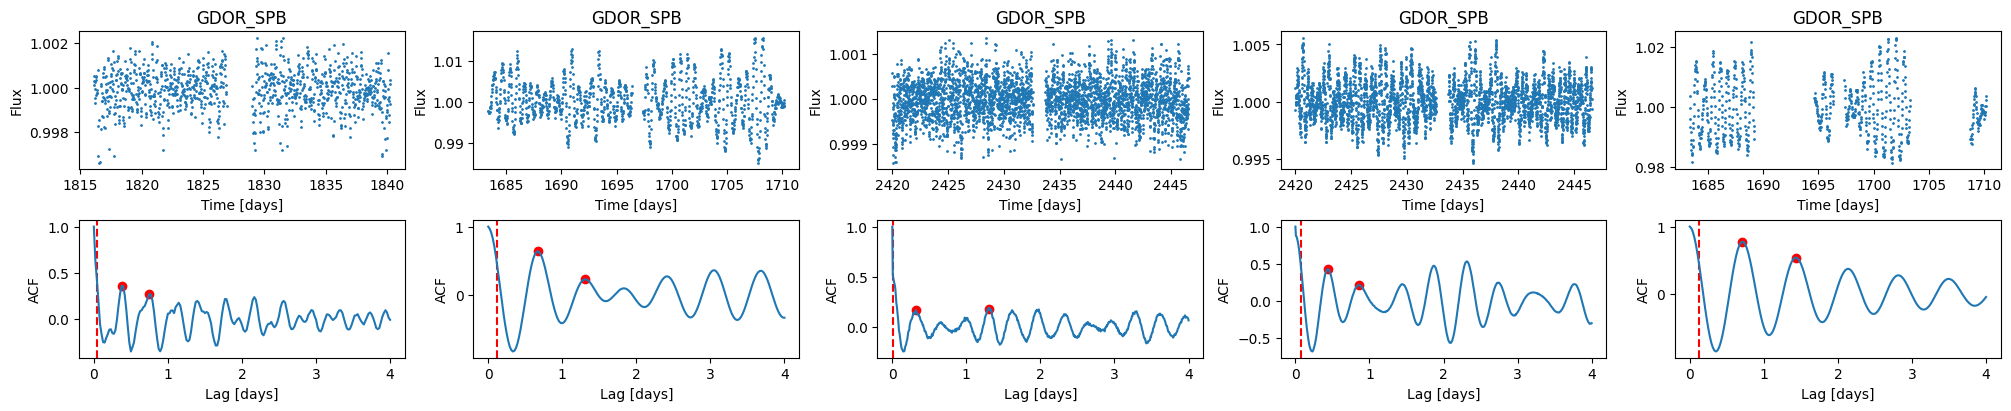

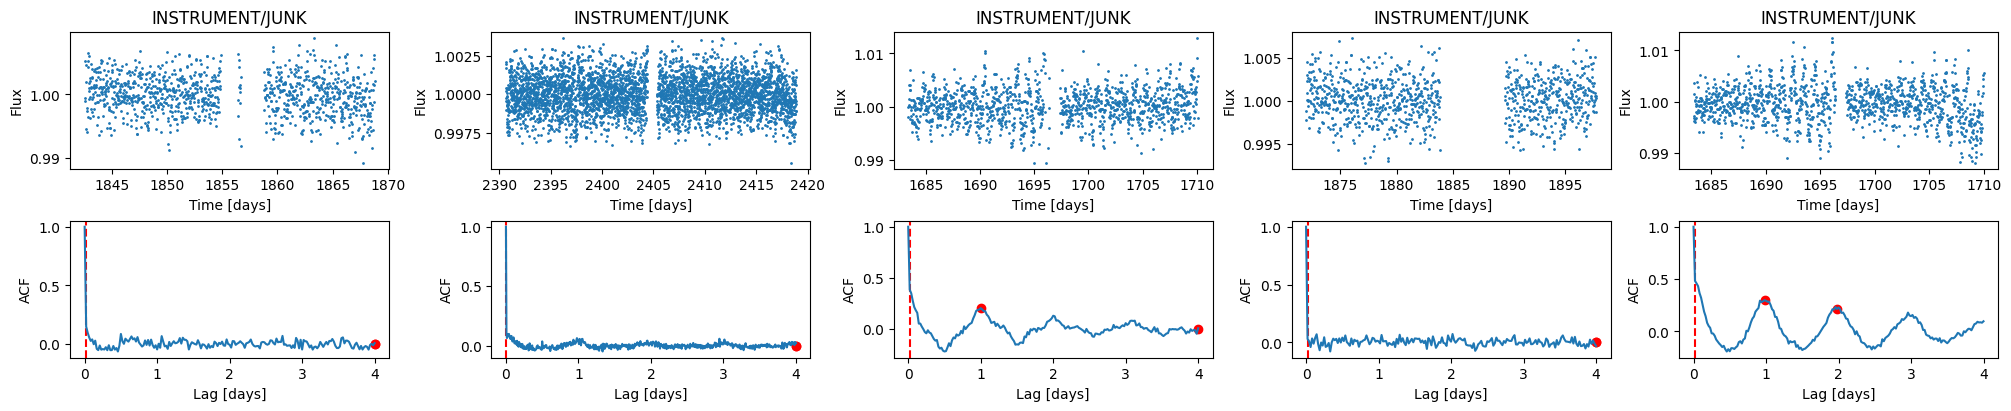

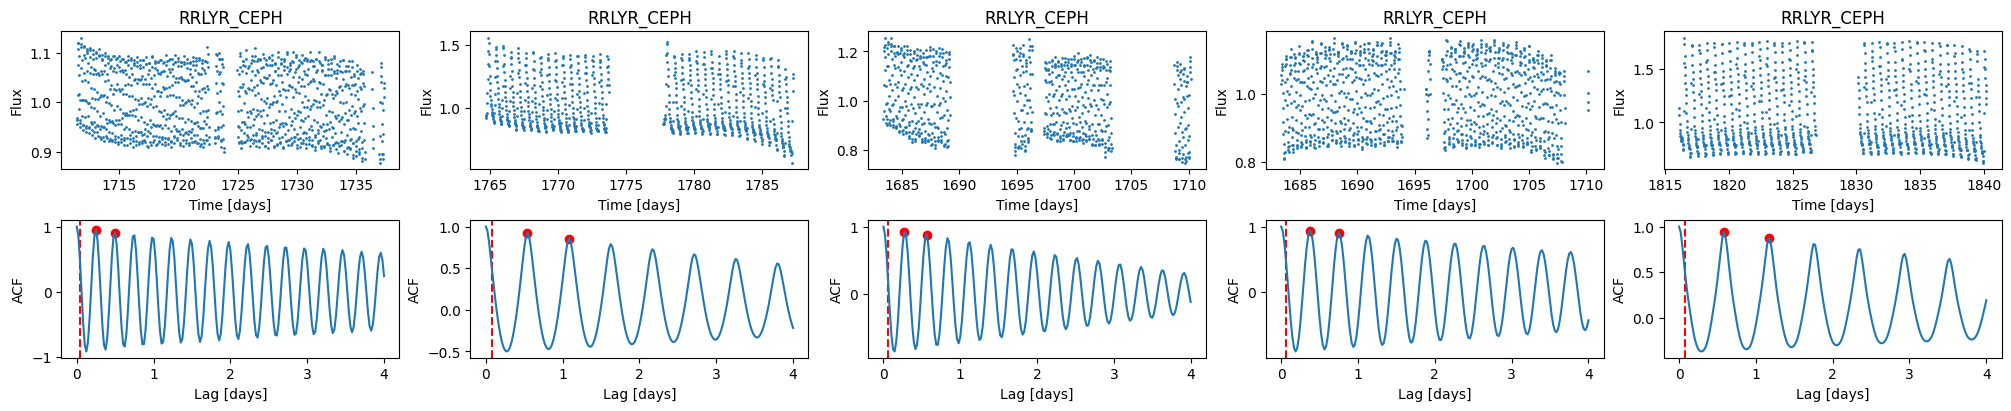

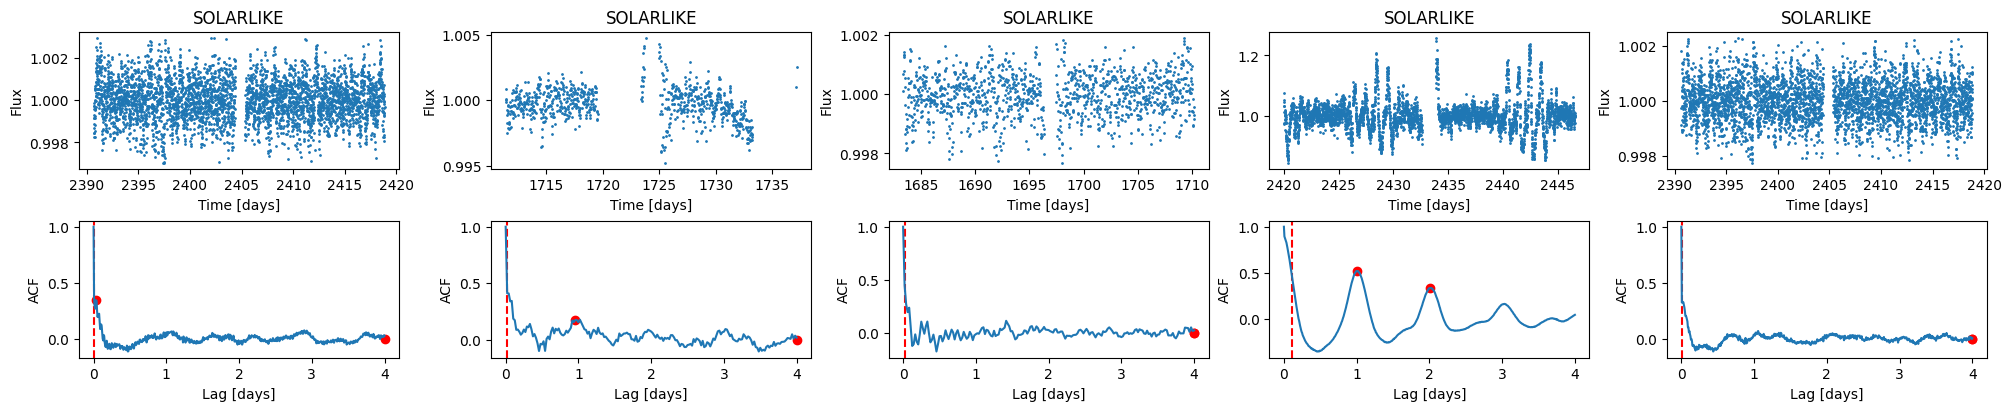

In [10]:
for name in class_names:
    fig, axs = plt.subplots(2, 5, figsize=(4*5, 4), constrained_layout=True)
    idxs = np.where(labels == name)[0]
    for idx, axs_ in zip(idxs, axs.T):
        plot_example_acf(times[idx], fluxes[idx], axs_)
        axs_[0].set_title(name)

In [11]:
%timeit -r10 -n10 autocorrelation_features(time, flux)
%timeit -r3 -n3 [autocorrelation_features(time, flux) for time, flux in zip(times, fluxes)]

785 μs ± 22.7 μs per loop (mean ± std. dev. of 10 runs, 10 loops each)
35 ms ± 145 μs per loop (mean ± std. dev. of 3 runs, 3 loops each)


# Fourier-series fit

Using the fundamental frequency we fit a four-component Fourier series and compute relative amplitudes/phases as Debosscher et al. 2007

We also save the the sum of squared residuals divided by the variance to compute the r2 coefficient of the fit.

{'fourier_amplitude_1': 0.0041719699140907625,
 'fourier_amplitude_2': 0.02785677561460467,
 'fourier_amplitude_3': 0.010724004546295483,
 'fourier_amplitude_4': 0.012509750678840382,
 'fourier_relative_phase_2': -0.41959546634663614,
 'fourier_relative_phase_3': -0.48904830051517134,
 'fourier_relative_phase_4': -0.9922238285785481,
 'fourier_r2_fit': 0.3209258905865562}

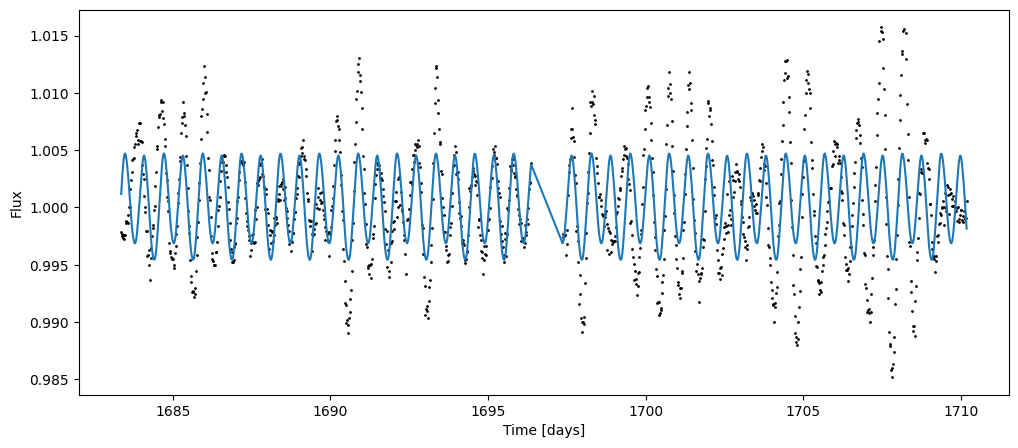

In [12]:
from frequency_domain_features import fourier_series_design_matrix, fit_fourier_series, fourier_series_features

best_freq = pg['ls_frequency_fundamental'] # From periodogram features

n_components = 4
X = fourier_series_design_matrix(time, best_freq, n_components)
theta, amplitudes, phases, _ = fit_fourier_series(time, flux, best_freq, n_components)

fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(time, flux, s=1, c='k')
ax.plot(time, np.dot(X, theta))
ax.set_xlabel('Time [days]')
ax.set_ylabel('Flux')

fourier_series_features(time, flux, best_freq, n_components, return_relative_amplitudes=True)

Note that the strongest peaks in the periodogram of this source are not related to the fundamental, hence why the fit does not explain the all the observed variability

- We could measure this with [IAR phi](https://academic.oup.com/mnras/article/481/4/4311/5094606)
- Or we could also fit with the top 2/3/4 frequencies when they are not harmonics of the fundamental

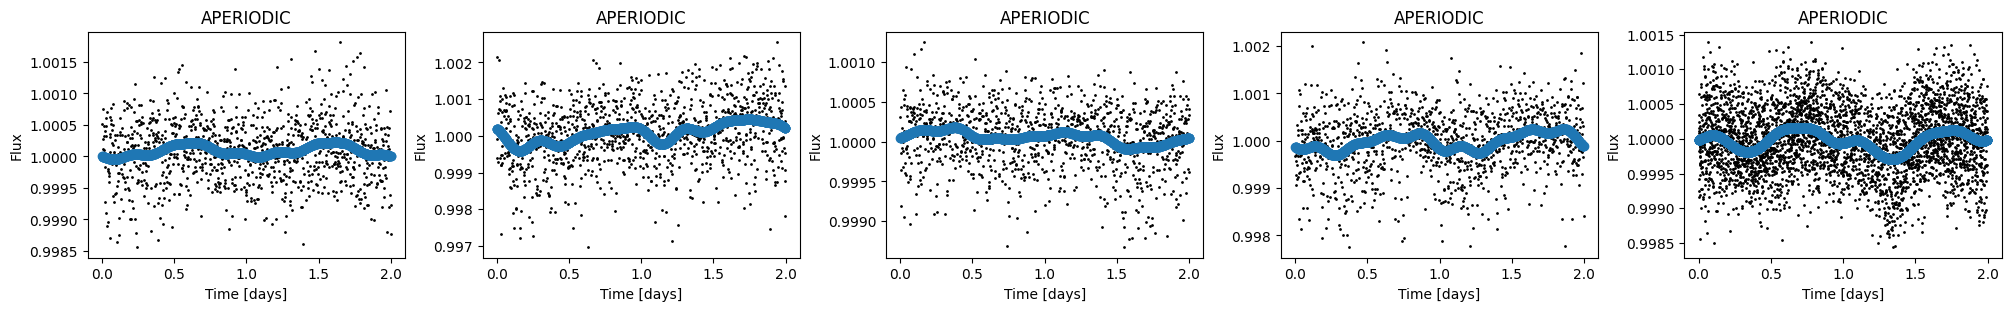

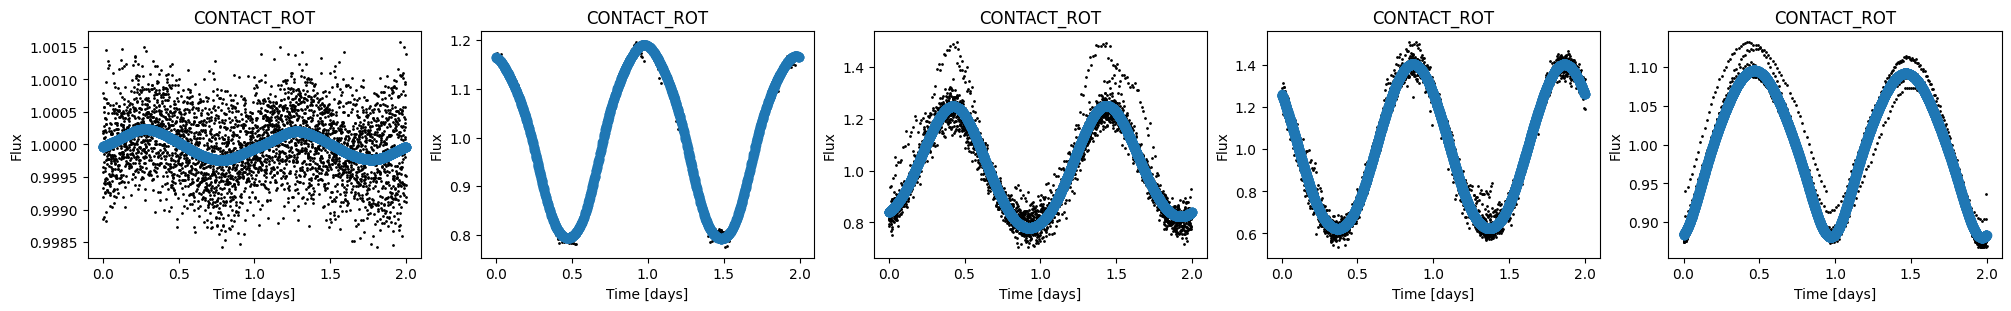

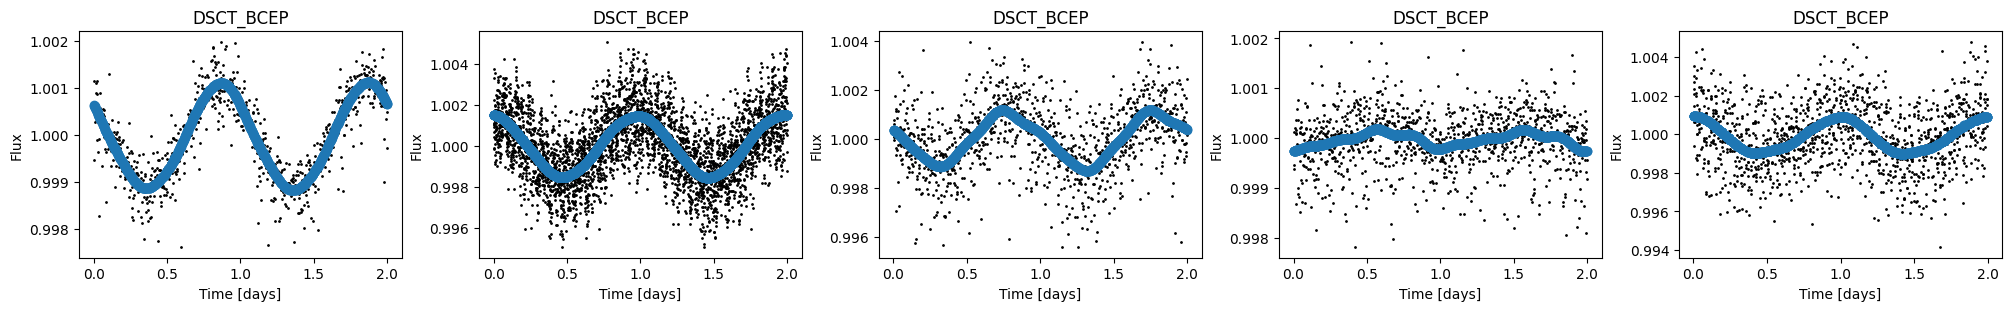

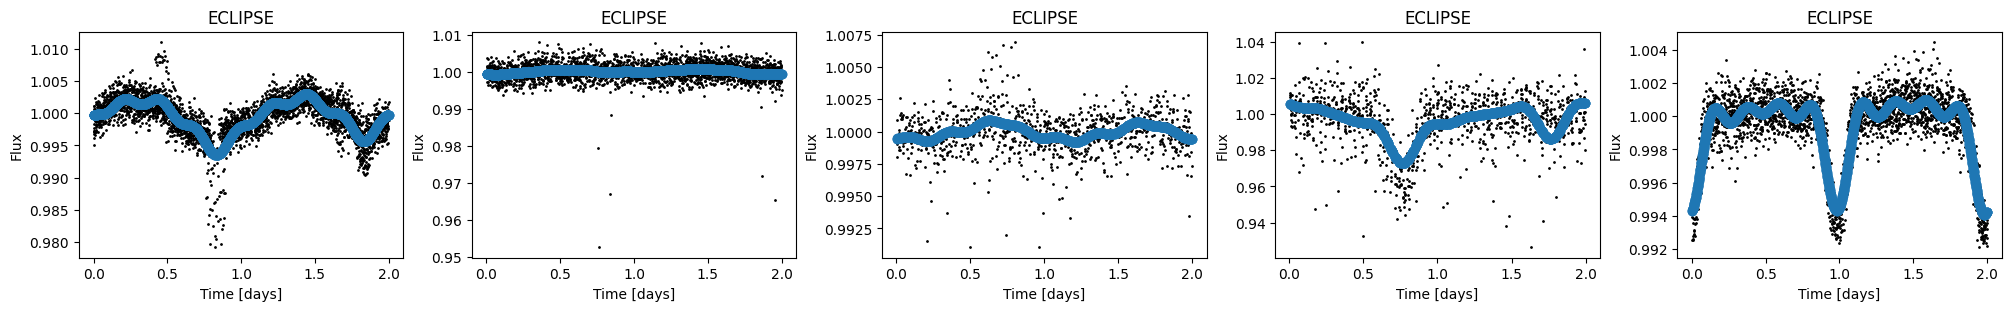

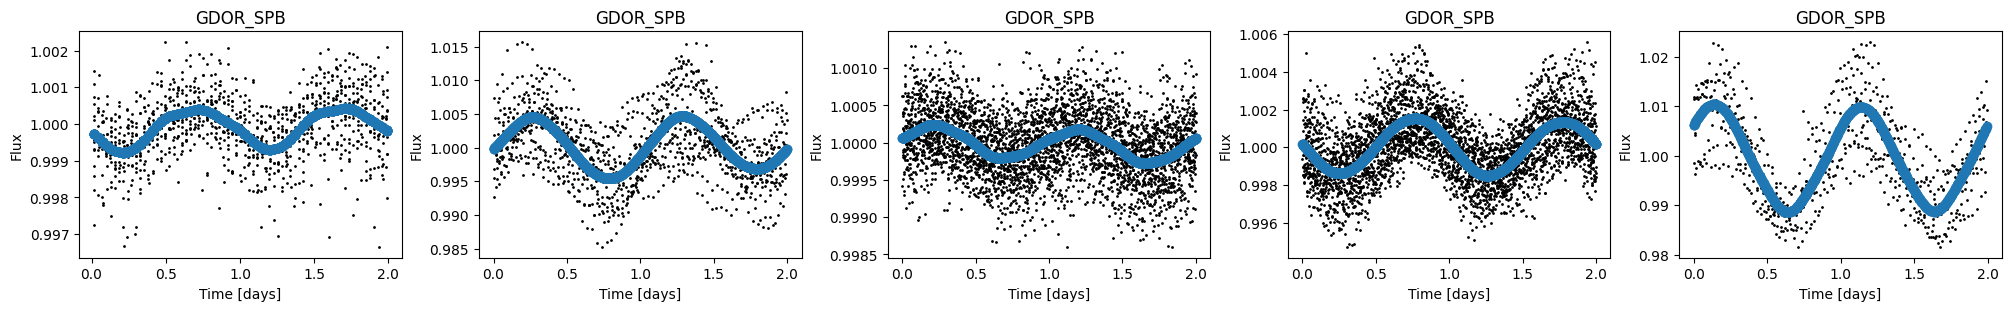

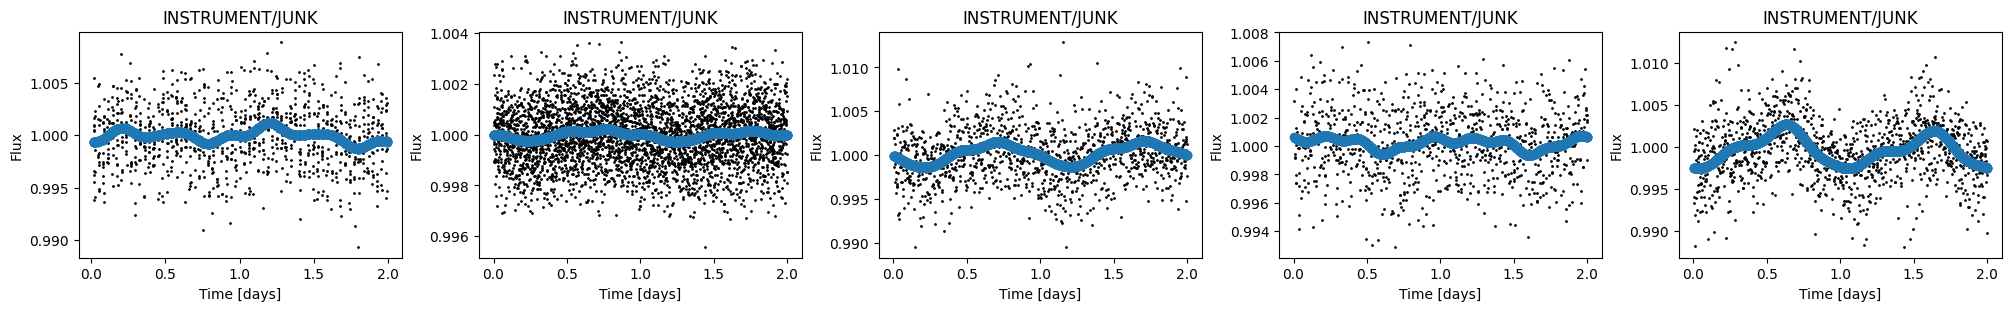

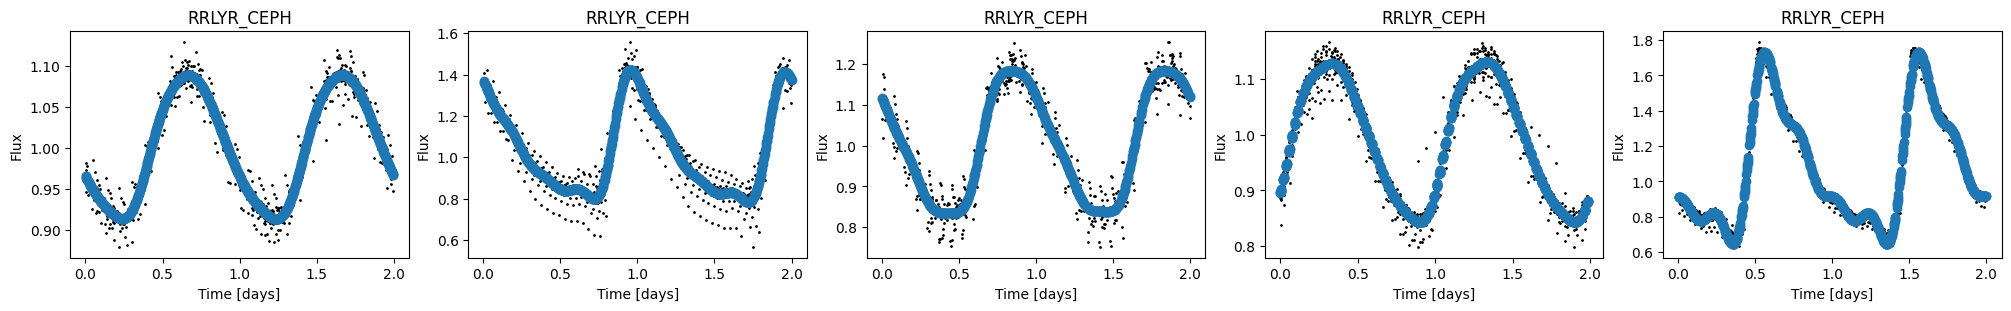

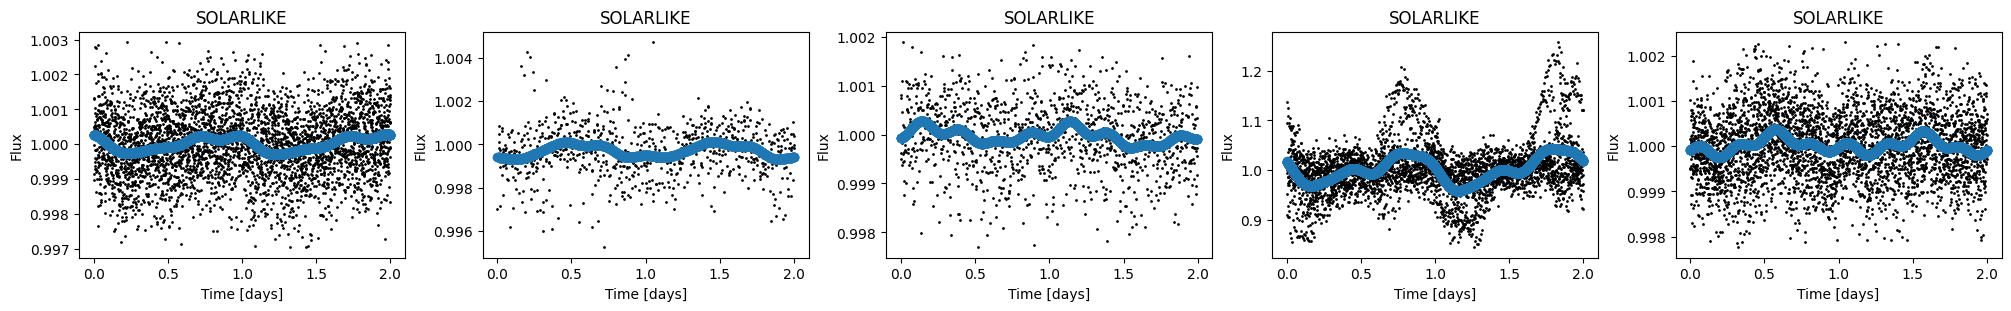

In [13]:
best_freqs = np.array([periodogram_features(time, flux)['ls_frequency_fundamental'] for time, flux in zip(times, fluxes)])

for name in class_names:
    fig, axs = plt.subplots(1, 5, figsize=(4*5, 3), constrained_layout=True)  
    idxs = np.where(labels == name)[0]
    for idx, ax in zip(idxs, axs):
        X = fourier_series_design_matrix(times[idx], best_freqs[idx], n_components)
        theta, amplitudes, phases, _ = fit_fourier_series(times[idx], fluxes[idx], best_freqs[idx], n_components)
        ax.set_title(name)
        phase = np.mod(times[idx], 2/best_freqs[idx])*best_freqs[idx]
        ax.scatter(phase, fluxes[idx], s=1, c='k')
        ax.scatter(phase, np.dot(X, theta))
        ax.set_xlabel('Time [days]')
        ax.set_ylabel('Flux')

In [14]:
%timeit -r3 -n3 fourier_series_features(time, flux, best_freq, n_components)
%timeit -r3 -n3 [fourier_series_features(time, flux, best_freq, n_components) for time, flux in zip(times, fluxes)]

648 μs ± 67.3 μs per loop (mean ± std. dev. of 3 runs, 3 loops each)
32.2 ms ± 203 μs per loop (mean ± std. dev. of 3 runs, 3 loops each)


# Barbara et al features

In [15]:
from barbara_kepler_features import barbara_features

for time, flux in zip(times, fluxes):
    display(barbara_features(time, flux))

{'AC_nl_001': 0.1886391147553786,
 'CO_trev_3_num': -0.11157966625993547,
 'ST_LocalExtrema_n100_medianmax': 1.2330177712207355,
 'SP_Summaries_welch_rect_peakPower_5': 0.00014736909141654635}

{'AC_nl_001': 0.1726510148189269,
 'CO_trev_3_num': 0.3625119310898391,
 'ST_LocalExtrema_n100_medianmax': 1.2269556390764267,
 'SP_Summaries_welch_rect_peakPower_5': 0.0007408177149318316}

{'AC_nl_001': 0.19200728272555184,
 'CO_trev_3_num': 0.2783785016730743,
 'ST_LocalExtrema_n100_medianmax': 1.2255272231789713,
 'SP_Summaries_welch_rect_peakPower_5': 0.00012309382001992255}

{'AC_nl_001': 0.21652700001808436,
 'CO_trev_3_num': -0.17966317971032406,
 'ST_LocalExtrema_n100_medianmax': 1.2045898144247589,
 'SP_Summaries_welch_rect_peakPower_5': 0.0005690722998629026}

{'AC_nl_001': 0.3262301864874851,
 'CO_trev_3_num': 0.1538543322443604,
 'ST_LocalExtrema_n100_medianmax': 1.7367067874890234,
 'SP_Summaries_welch_rect_peakPower_5': 0.0005868342554165287}

{'AC_nl_001': 0.5516631755391507,
 'CO_trev_3_num': -0.012134936614392074,
 'ST_LocalExtrema_n100_medianmax': 1.5735206644981856,
 'SP_Summaries_welch_rect_peakPower_5': 0.0009980907410939751}

... (30 outputs left out)

{'AC_nl_001': 0.30862017756517107,
 'CO_trev_3_num': 0.11344333544857861,
 'ST_LocalExtrema_n100_medianmax': 0.9773512808277236,
 'SP_Summaries_welch_rect_peakPower_5': 0.0021722251630193062}

{'AC_nl_001': 0.3491002072544315,
 'CO_trev_3_num': -0.18496185142116964,
 'ST_LocalExtrema_n100_medianmax': 1.3217029957712545,
 'SP_Summaries_welch_rect_peakPower_5': 0.0004361388193287799}

{'AC_nl_001': 0.7295534820215954,
 'CO_trev_3_num': 0.14487140181456518,
 'ST_LocalExtrema_n100_medianmax': 0.8463206769826921,
 'SP_Summaries_welch_rect_peakPower_5': 15.417872857721358}

{'AC_nl_001': 0.2542480763071987,
 'CO_trev_3_num': 0.1116271183878811,
 'ST_LocalExtrema_n100_medianmax': 1.9252251144179413,
 'SP_Summaries_welch_rect_peakPower_5': 0.0009027008519708191}